# Laboratorio 03 — Reglas de asociación

**Datos:** 13 archivos DBF de Visual FoxPro con las facturas de una tienda de conveniencia.

Este notebook muestra el desarrollo del taller. La lógica vive en `src/`, por tres razones:
el benchmark necesita correr **fuera** del kernel de Jupyter (su overhead contaminaría las
mediciones de tiempo), el código queda cubierto por pruebas, y el notebook se mantiene legible.

Para reproducirlo desde cero:

```bash
make build      # imagen Docker con Python 3.12, mlxtend y TeX Live
make d-all      # tests, ETL, EDA, día de semana, reglas, benchmark, notebook y PDF
```

In [1]:
import sys

sys.path.insert(0, "/lab")

import pandas as pd

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

from src.parse import OUTPUT_DIR

TABLAS = OUTPUT_DIR / "tables"


def tabla(nombre, n=None):
    """Lee una tabla ya generada por el pipeline."""
    df = pd.read_csv(TABLAS / nombre)
    return df.head(n) if n else df

## 1. Documentación de los algoritmos

**apriori** recorre el retículo de itemsets por niveles: genera candidatos de tamaño *k+1*
a partir de los frecuentes de tamaño *k* y vuelve a recorrer los datos para contarlos. Se
apoya en la propiedad de antimonotonía: si un itemset no es frecuente, ningún superconjunto
suyo puede serlo.

**fp-growth** evita generar candidatos. Comprime las transacciones en un árbol de prefijos
(FP-tree) y extrae los itemsets frecuentes recorriendo ese árbol de forma recursiva.

Consecuencia práctica, que este laboratorio mide: **ambos devuelven exactamente el mismo
conjunto de itemsets frecuentes**; lo que cambia es el costo, y la diferencia se amplía
cuando el soporte mínimo baja, porque es ahí donde apriori genera más candidatos.

## 2. Lectura y parseo: line-item y factura

Dos diferencias entre lo que dice el enunciado y lo que traen los archivos:

1. El enunciado describe texto con **una línea por factura**. Los DBF traen **una línea por
   line-item**, así que hay que *agrupar*, no *dividir*.
2. La descripción del producto es un campo `Varchar` de Visual FoxPro: su **último byte
   guarda la longitud**. Un lector que no lo interprete deja ese byte pegado al nombre.
   Por eso `src/dbf_reader.py` es propio y no `dbfread`.

In [2]:
from src.dbf_reader import DBFTable
from src.parse import archivos_dbf

ruta = [r for r in archivos_dbf() if r.name == "fc01042024.DBF"][0]
tabla_dbf = DBFTable(ruta)
print(tabla_dbf)
print("tipo del campo DESCRI:", tabla_dbf.field("DESCRI").type, "longitud:", tabla_dbf.field("DESCRI").length)

DBFTable('fc01042024.DBF', version=0x32, records=1168, fields=51)
tipo del campo DESCRI: V longitud: 254


In [3]:
# El byte de longitud, visto de cerca.
campo = tabla_dbf.field("DESCRI")
crudo = tabla_dbf.raw_record(0)[1 + campo.offset : 1 + campo.offset + campo.length]

print("lectura ingenua :", repr(crudo.decode("latin-1").strip()))
print("ultimo byte     :", crudo[-1], "<- es la longitud, no una letra")
print("lectura correcta:", repr(next(iter(tabla_dbf))["DESCRI"]))

lectura ingenua : 'LUCKY DAIQUIRI X 10                                                                                                                                                                                                                                          B'
ultimo byte     : 66 <- es la longitud, no una letra
lectura correcta: 'LUCKY DAIQUIRI X 10'


In [4]:
# Objetos de dominio que pide el enunciado.
from src.parse import cargar_facturas

facturas = cargar_facturas([ruta])
# La de más renglones entre las ventas: tomar el máximo global devolvía una
# cotización (CODTRA 'CO'), que no es una compra de un cliente.
ventas = [x for x in facturas if x.tipo_doc == "FA"]
f = max(ventas, key=lambda x: x.n_lineas)

print(f"Factura {f.numero}  fecha={f.fecha}  caja={f.caja}  tipo={f.tipo_doc}")
print(f"  total={f.total:,.0f}  impuesto={f.total_impuesto:,.0f}  items={f.total_items:.0f}  renglones={f.n_lineas}")
for item in f.items[:5]:
    print(f"  - {item.producto[:34]:36s} x{item.cantidad:>5.1f} @ {item.precio_unitario:>10,.2f} = {item.subtotal:>10,.2f}")
print(f"\ncanasta (productos distintos): {f.canasta[:5]} ...")

Factura fc01042024|2|FA|61862  fecha=2024-04-01  caja=2  tipo=FA
  total=17,907  impuesto=3,093  items=13  renglones=12
  - GUMYS 20 GR                          x  1.0 @   1,344.54 =   1,345.00
  - GUMYS 20 GR                          x  1.0 @   1,344.54 =   1,345.00
  - GUMYS 20 GR                          x  1.0 @   1,344.54 =   1,345.00
  - GUMYS 20 GR                          x  1.0 @   1,344.54 =   1,345.00
  - GUMYS 20 GR                          x  1.0 @   1,344.54 =   1,345.00

canasta (productos distintos): ['GUMYS 20 GR', 'PONKY 33 GR', 'AGUA CIELO CON GAS 620ML'] ...


### ETL

El procesamiento está en tres capas —bronze crudo, silver limpio, gold analítico— con
contratos de datos y caché por SHA-256 de cada archivo de origen. Se ejecuta con
`make etl` y aquí solo se leen sus resultados.

In [5]:
from src.parse import cargar

items, fact = cargar()
print(f"{len(items):,} renglones · {len(fact):,} facturas · {items['producto'].nunique():,} productos")
items.head(3)

147,411 renglones · 68,807 facturas · 1,265 productos


,factura,archivo,fecha,caja,tipo_doc,consecutivo,orden_fisico,producto,codigo,cantidad,precio_unitario,subtotal,iva,descuento,tasa_iva,unidad,costo,descuadre,cuadra,linea,timestamp,hora,dia_semana,dia_num,es_fin_semana,tipo_dia,semana_iso,panel,es_atipico,n_dias_observados
0,fc01042024|2|FA|61642,fc01042024.DBF,2024-04-01,2,FA,61642,0,LUCKY DAIQUIRI X 10,7702303006415,1.0,4873.95,4874.0,926.0,0.0,19.0,94,4757.5124,0.05,True,1,2024-04-01 07:01:09.767442,7,lunes,0,False,habil,2024-W14,parcial,False,2
1,fc01042024|2|FA|61643,fc01042024.DBF,2024-04-01,2,FA,61643,1,TAPABOCAS X UND,7709468986514,1.0,504.20,504.0,96.0,0.0,19.0,94,161.5450,0.20,True,1,2024-04-01 07:03:29.302326,7,lunes,0,False,habil,2024-W14,parcial,False,2
2,fc01042024|2|FA|61643,fc01042024.DBF,2024-04-01,2,FA,61643,2,DESCONGEL GRIPA,322,1.0,1500.00,1500.0,0.0,0.0,0.0,94,1000.0000,0.00,True,2,2024-04-01 07:03:29.302326,7,lunes,0,False,habil,2024-W14,parcial,False,2


In [6]:
# Control de calidad del ETL: los contratos que se verificaron al construir las tablas.
tabla("00_calidad_datos.csv")

,control,severidad,resultado,valor,detalle
0,bronze: registros <= los del header DBF,falla,ok,"147,413 de 147,413",NaN
1,bronze: registros borrados omitidos,aviso,ok,0,NaN
2,bronze: un sha256 por archivo,falla,ok,13,NaN
3,bronze: DESCRI sin caracteres de control,falla,ok,0,el Varchar VFP quedo mal recortado
4,bronze: columna de orden fisico presente,falla,ok,_fila,NaN
5,calendario: domingo/ contiene solo domingo,falla,ok,domingo,la fecha del nombre se leyo como ddmmyyyy
6,calendario: jueves/ contiene solo jueves,falla,ok,jueves,la fecha del nombre se leyo como ddmmyyyy
7,calendario: lunes/ contiene solo lunes,falla,ok,lunes,la fecha del nombre se leyo como ddmmyyyy
8,calendario: martes/ contiene solo martes,falla,ok,martes,la fecha del nombre se leyo como ddmmyyyy
9,calendario: miercoles/ contiene solo miercoles,falla,ok,miercoles,la fecha del nombre se leyo como ddmmyyyy


**Los DBF no traen hora.** La fecha sale del nombre del archivo; la hora se *estima*
repartiendo las facturas de cada caja, en su orden real de facturación, sobre una jornada
supuesta de 07:00 a 22:00. Sirve para la posición dentro de la jornada, **no** para horas
absolutas, y el conteo por hora queda constante por construcción.

In [7]:
from src.etl.load import leer_dim_calendario

leer_dim_calendario()[["fecha", "dia_semana", "tipo_dia", "semana_iso", "panel", "n_dias_observados", "nota"]]

,fecha,dia_semana,tipo_dia,semana_iso,panel,n_dias_observados,nota
0,2024-03-09,sabado,fin de semana,2024-W10,completa,2,
1,2024-03-10,domingo,fin de semana,2024-W10,completa,2,
2,2024-03-11,lunes,habil,2024-W11,completa,2,
3,2024-03-12,martes,habil,2024-W11,completa,2,
4,2024-03-13,miercoles,habil,2024-W11,completa,2,
5,2024-03-14,jueves,habil,2024-W11,completa,2,
6,2024-03-15,viernes,habil,2024-W11,completa,1,
7,2024-03-24,domingo,fin de semana,2024-W12,atipico,2,Domingo de Ramos (inicio de Semana Santa)
8,2024-04-01,lunes,habil,2024-W14,parcial,2,semana siguiente a Semana Santa
9,2024-04-02,martes,habil,2024-W14,parcial,2,semana siguiente a Semana Santa


## 3. Análisis descriptivo

### 3.a Generalidades

In [8]:
tabla("01_resumen_general.csv")

,metrica,valor
0,Registros (line-items),"147,411"
1,Facturas,"68,807"
2,Archivos / dias cubiertos,13 / 13
3,Rango de fechas,2024-03-09 a 2024-04-06
4,Productos distintos,"1,265"
5,Renglones por factura (media),2.14
6,Renglones por factura (mediana),2
7,Renglones por factura (maximo),49
8,Unidades por factura (media),6.77
9,Facturas de un solo producto,"28,203 (41.0%)"


In [9]:
# Tamaño de canasta: el dato que obliga a usar soportes bajos.
tabla("03_tamano_canasta.csv", 8)

,productos_en_factura,facturas,porcentaje
0,1,28203,40.988562
1,2,22752,33.066403
2,3,11305,16.430014
3,4,3827,5.561934
4,5,1352,1.964916
5,6,441,0.640923
6,7,235,0.341535
7,8,136,0.197654


### 3.b y 3.c Producto más vendido, y comparación con el TOP 10

In [10]:
tabla("06_top10.csv")[["producto", "facturas", "unidades", "soporte", "pct_del_lider", "acumulado_pct"]]

,producto,facturas,unidades,soporte,pct_del_lider,acumulado_pct
0,EMPANADAS,7211,21099.0,0.104800,100.000000,5.045409
1,PASTELES. PALITOS,2967,8109.0,0.043121,41.145472,7.121367
2,JUGO HIT 500 ML,2609,7997.0,0.037918,36.180835,8.946838
3,COCA COLA FLEXI 400 ML,2363,5473.0,0.034342,32.769380,10.600188
4,CANDYRANCH 13GR,2050,6676.0,0.029793,28.428789,12.034536
5,TRIDENT 10 GR,1946,2089.0,0.028282,26.986548,13.396118
6,SANDWICH SENCILLO,1913,6857.0,0.027802,26.528914,14.734610
7,PASTILLAS CHAO CEREZA,1863,3700.0,0.027076,25.835529,16.038119
8,HALLS BARRA 25 GR,1717,1788.0,0.024954,23.810845,17.239473
9,MENTA CHAO LÍNEA,1524,2222.0,0.022149,21.134378,18.305789


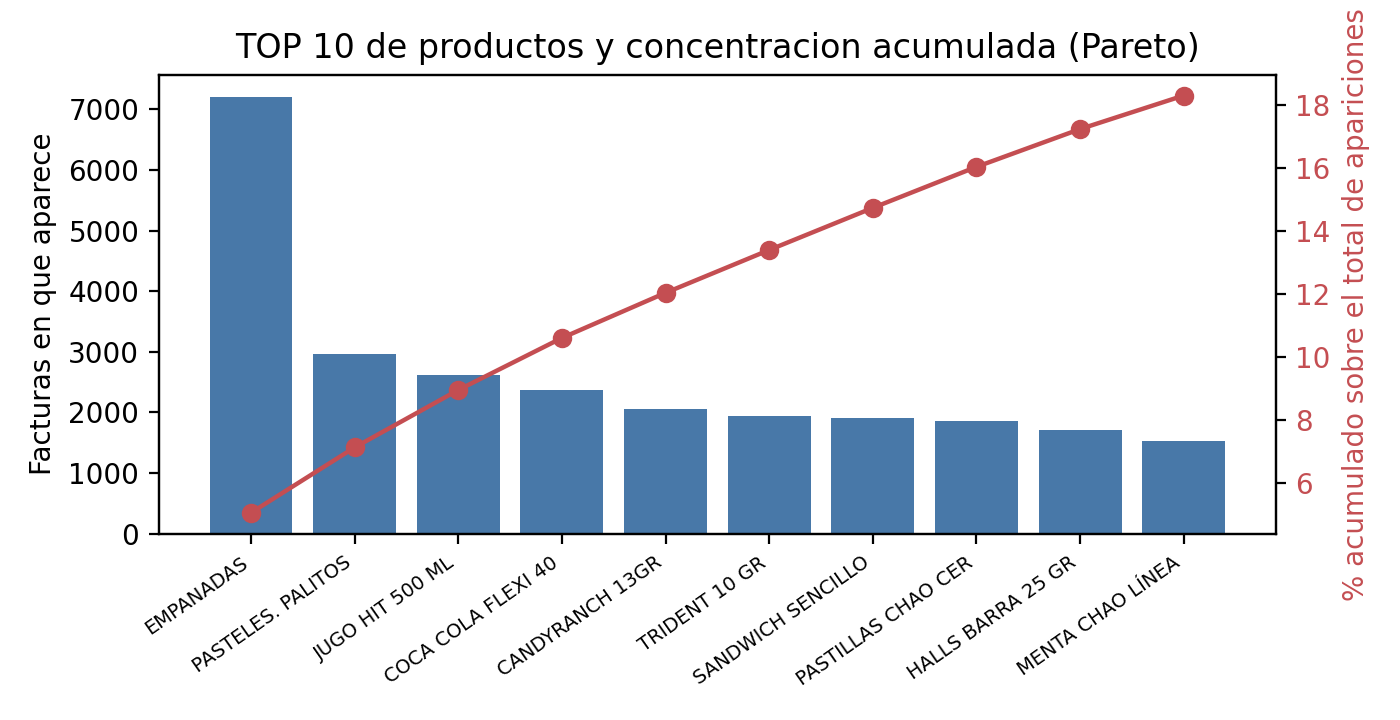

In [11]:
from IPython.display import Image, display

display(Image(filename=str(OUTPUT_DIR / "figs" / "06_top10_pareto.png")))

### 3.d Producto menos vendido: ¿se vendió solo o acompañado?

In [12]:
tabla("08_menos_vendidos.csv", 10)[["producto", "facturas", "unidades", "veces_vendido_solo", "veces_acompanado", "acompanantes_top"]]

,producto,facturas,unidades,veces_vendido_solo,veces_acompanado,acompanantes_top
0,ANTIOQUEÑO AZUL 375 ML,1,1.0,1,0,NaN
1,ATUN RALLADO ACEITE 150GR,1,1.0,0,1,"FUZE TEA 400ML, PAPAS RIZADAS MAYONESA 105 GR"
2,BABY JOHNNY'S 30GR,1,1.0,0,1,AGUA CIELO LITRO
3,BACARDI LIMON 375 ML,1,1.0,1,0,NaN
4,BOLSA DELIRIO GRANDE,1,1.0,0,1,"CANDY TOY RAPTOR 12GR, JUMBO DOTS 30GR"
5,BOLSA PEQUEÑA DELIRIO,1,1.0,0,1,"ESFEROS MINAS SURTIDOS, CAMARAS PROJECTOR 12GR..."
6,BORRADOR RETRACTIL OSO,1,1.0,1,0,NaN
7,BOTELLON AGUA,1,1.0,0,1,"JUGO VALLE 1.5 L, COCA COLA 3 LITROS, COCA COL..."
8,CINTA DE ENMASCARAR DELGADA,1,1.0,0,1,TODO RICO BBQ 45GR
9,CORTA UÑAS,1,1.0,0,1,JUGO HIT 500 ML


### Extra: día de la semana

Los 13 archivos son dos semanas desiguales. Solo el tramo 9–15 de marzo trae los siete días
una vez cada uno: es el único panel donde comparar días es limpio. El **índice** es el valor
del día dividido por el promedio semanal (1.00 = promedio).

In [13]:
tabla("15_comparativa_dia_semana.csv")[["dia_semana", "tipo_dia", "facturas", "ticket_promedio", "canasta_promedio", "indice_facturas", "delta_pct_facturas"]]

,dia_semana,tipo_dia,facturas,ticket_promedio,canasta_promedio,indice_facturas,delta_pct_facturas
0,lunes,habil,5978.0,12422.260942,2.079625,0.899,-10.1
1,martes,habil,6551.0,16070.538683,2.099221,0.985,-1.5
2,miercoles,habil,7151.0,15522.250722,2.076213,1.075,7.5
3,jueves,habil,7737.0,17092.310755,2.097454,1.163,16.3
4,viernes,habil,8477.0,16589.340619,2.090480,1.275,27.5
5,sabado,fin de semana,5239.0,12598.857589,2.087803,0.788,-21.2
6,domingo,fin de semana,5421.0,12562.025809,2.086700,0.815,-18.5


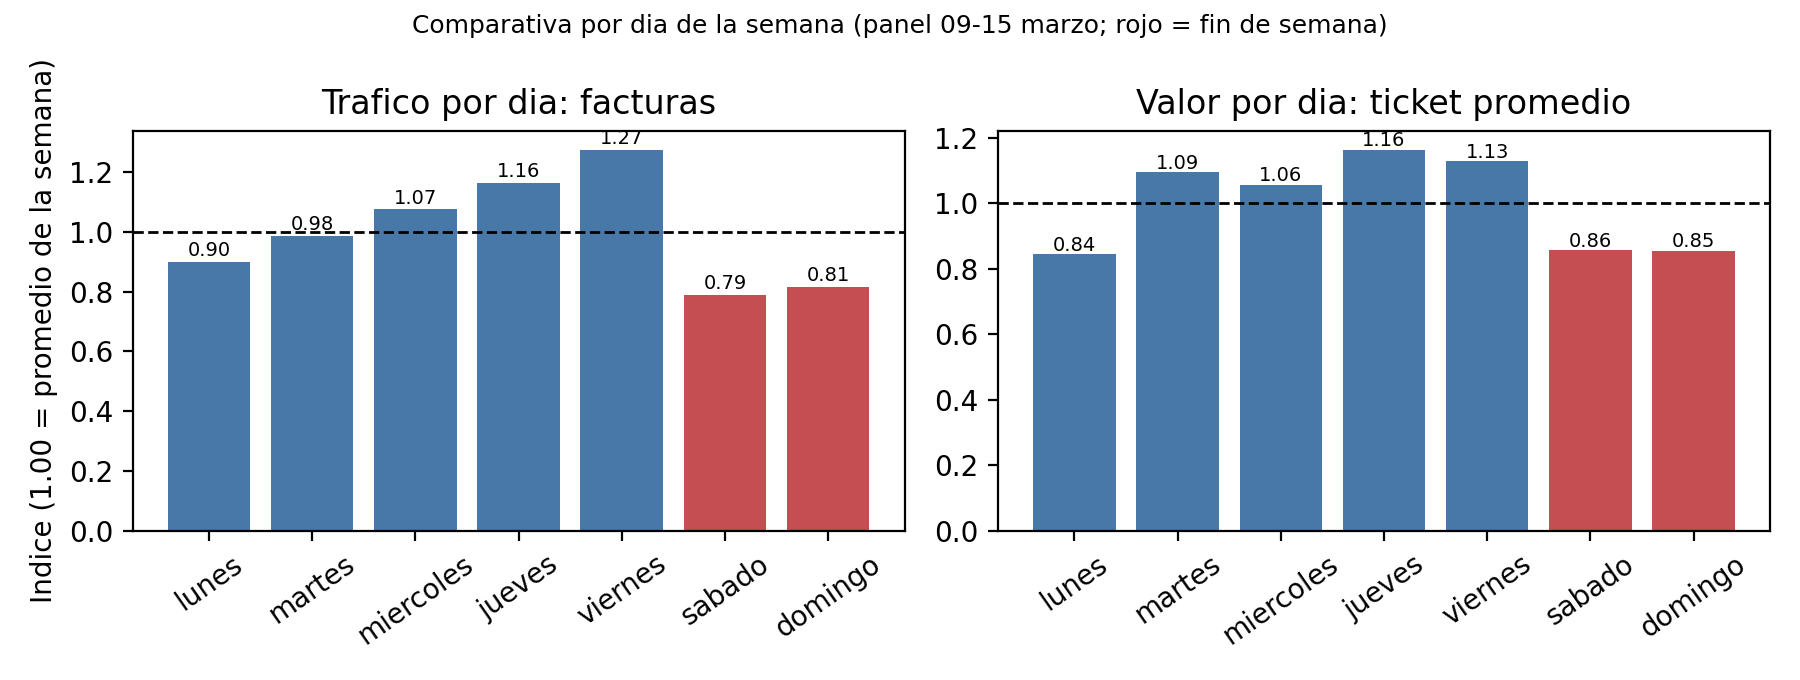

,clave,valor
0,panel,completa
1,dias,7
2,facturas,46554
3,hipotesis nula,las facturas se reparten por igual entre los 7...
4,chi2,1313.2
5,grados de libertad,6
6,p_valor,1.536e-280
7,se rechaza al 1%,True
8,lectura,el dia de la semana si afecta el trafico


In [14]:
display(Image(filename=str(OUTPUT_DIR / "figs" / "15_indice_por_dia.png")))
tabla("15b_test_uniformidad_dia.csv")

## 4. Hipótesis

A partir del análisis anterior, tres hipótesis falsables:

- **H1.** La canasta está dominada por consumo inmediato, así que las reglas fuertes unirán
  un alimento con una bebida, no categorías distintas.
- **H2.** Con canasta media de 2,1 productos y 41 % de facturas de un solo ítem, el soporte
  alcanzable para pares es muy bajo: los combos entre un producto muy vendido y uno poco
  vendido **no** tendrán soporte suficiente y solo aparecerán vía *lift*, con riesgo de ser
  espurios.
- **H3.** Los productos de cola larga aparecen sobre todo en facturas de un solo ítem, así
  que no son candidatos a combo: son compras de misión única.

Cada una se acepta o se rechaza al final, con el número que la decide.

## 5. Reglas de asociación con mlxtend

(El enunciado dice *xlmtend*; la biblioteca es **mlxtend**.)

In [15]:
from src.rules import SOPORTE_ANALISIS, minar

itemsets, reglas, n_trans = minar(items, min_support=SOPORTE_ANALISIS)
print(f"{n_trans:,} transacciones · soporte {SOPORTE_ANALISIS} (>= {round(SOPORTE_ANALISIS * n_trans)} facturas)")
print(f"{len(itemsets):,} itemsets frecuentes · {len(reglas):,} reglas")

68,807 transacciones · soporte 0.0005 (>= 34 facturas)
866 itemsets frecuentes · 434 reglas


### 5.a–5.d Comparación apriori vs fp-growth

El benchmark corre **fuera del notebook** (`make bench`): 5 soportes × 4 valores de
`max_len` = 20 combinaciones por algoritmo, 3 repeticiones cada una, con límite de tiempo
por corrida y medición de memoria pico. Aquí se leen sus resultados.

In [16]:
tabla("14_entorno.csv")

,clave,valor
0,python,3.12.15
1,plataforma,Linux-6.12.76-linuxkit-aarch64-with-glibc2.41
2,maquina,aarch64
3,cpus,10
4,mlxtend,0.23.4
5,pandas,2.2.3
6,numpy,2.1.3
7,timeout_s,600
8,repeticiones,3


In [17]:
tabla("12_benchmark_comparativa.csv")

,min_support,max_len,apriori,fpgrowth,speedup_fpgrowth
0,0.0002,2.0,NaN,80.166758,NaN
1,0.0002,3.0,NaN,113.392004,NaN
2,0.0002,4.0,NaN,144.102028,NaN
3,0.0002,NaN,NaN,186.391795,NaN
4,0.0005,2.0,NaN,10.643249,NaN
5,0.0005,3.0,NaN,11.365122,NaN
6,0.0005,4.0,NaN,11.716006,NaN
7,0.0005,NaN,NaN,11.534841,NaN
8,0.0010,2.0,NaN,3.013053,NaN
9,0.0010,3.0,NaN,2.892601,NaN


In [18]:
# Prueba de equivalencia: misma firma de itemsets => mismo resultado, distinto costo.
# Solo cuentan las combinaciones que ambos algoritmos completaron: donde apriori se
# quedó sin memoria no hay nada que contrastar.
equivalencia = tabla("13_equivalencia_itemsets.csv")
if "comparable" in equivalencia.columns:
    comparables = int(equivalencia["comparable"].sum())
    iguales = int(equivalencia["identicos"].sum())
    sin_comparar = len(equivalencia) - comparables
    print(f"itemsets idénticos en {iguales} de {comparables} combinaciones comparables")
    print(f"{sin_comparar} combinaciones sin comparar: apriori no completó por memoria")
equivalencia

itemsets idénticos en 8 de 8 combinaciones comparables
12 combinaciones sin comparar: apriori no completó por memoria


,min_support,max_len,apriori,fpgrowth,comparable,identicos
0,0.0002,2.0,NaN,05f37426373c2397,False,False
1,0.0002,3.0,NaN,fd2e61050094a2dd,False,False
2,0.0002,4.0,NaN,50ecaa79b5a4c5eb,False,False
3,0.0002,NaN,NaN,77d0c0a58ba8e1fa,False,False
4,0.0005,2.0,NaN,20e3143ba0a9e097,False,False
5,0.0005,3.0,NaN,75604e3c74fe6261,False,False
6,0.0005,4.0,NaN,dae6201b8dafb3c8,False,False
7,0.0005,NaN,NaN,89e025771a8aad20,False,False
8,0.0010,2.0,NaN,a6f3e5d9fbb58b5e,False,False
9,0.0010,3.0,NaN,a6f3e5d9fbb58b5e,False,False


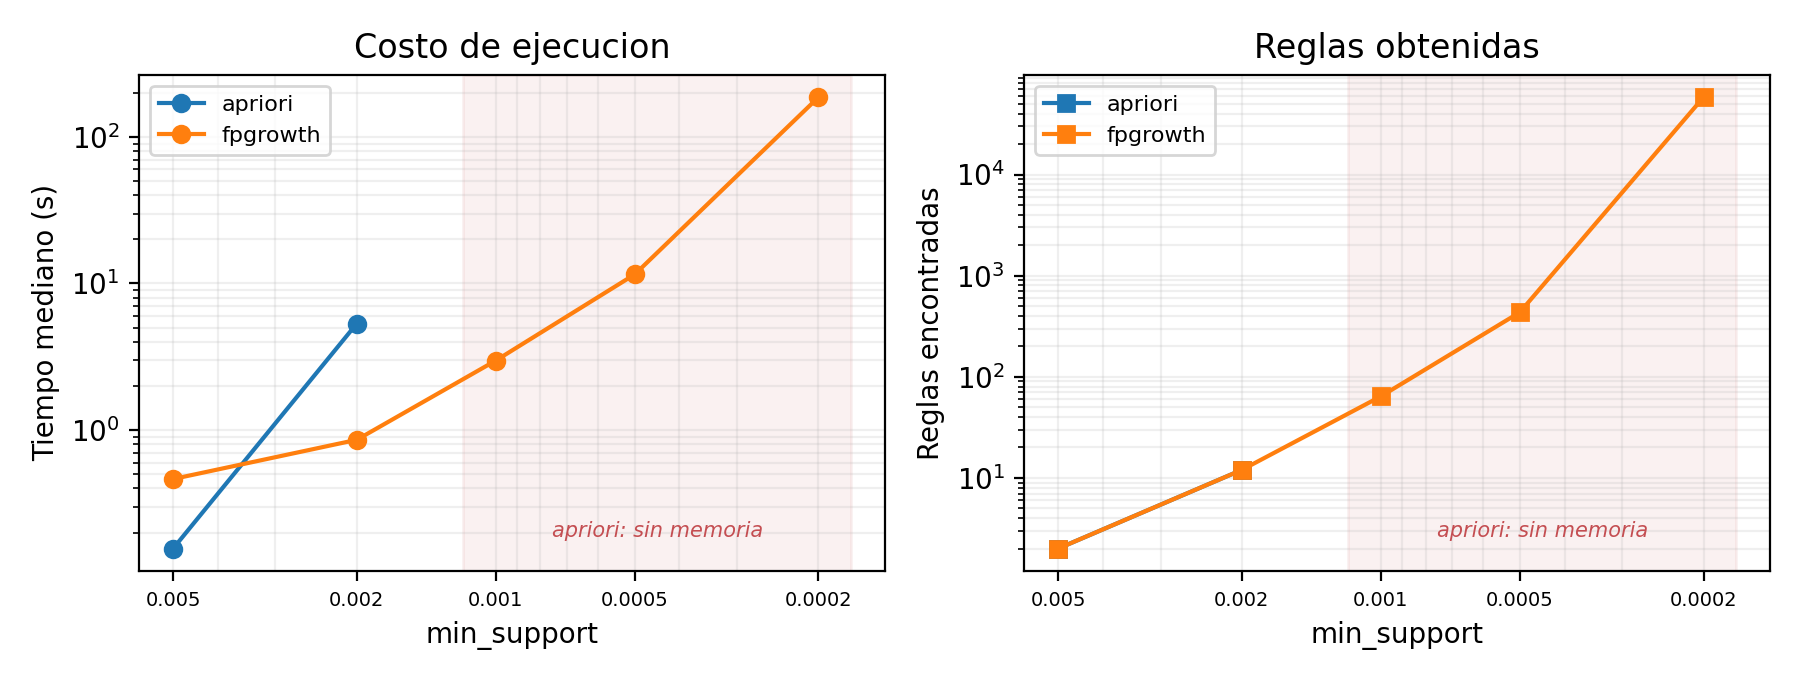

In [19]:
display(Image(filename=str(OUTPUT_DIR / "figs" / "10_benchmark.png")))

## 6. Preguntas del taller

### 1. Reglas predecibles entre productos, k = 1

`es_armado` separa las reglas entre insumos de regalo (empaque, caja, mug), que son ciertas
pero triviales, de las reglas entre productos de consumo, que son las que pide el enunciado
con su ejemplo *avena → pandebono*.

In [20]:
p1 = tabla("21_p1_reglas_k1.csv")
print("— de consumo —")
display(p1[~p1["es_armado"]].head(8))
print("— de armado de regalo (triviales) —")
display(p1[p1["es_armado"]].head(4))

— de consumo —


,antecedente,consecuente,facturas,support,confidence,lift,es_armado
3,PLANTERS 49GR,CHOCOLATE CORAZON UND,40,0.000581,0.655738,283.769461,False
4,PLANTERS 49GR,MELOSITAS 40GR,39,0.000567,0.639344,316.484609,False
6,SOBRE MANILA,IMPRESIONES,56,0.000814,0.571429,87.373968,False
8,MOCACHINO 7OZ,EMPANADAS,58,0.000843,0.504348,4.812462,False
10,CERVEZA HEINEKEN 250 ML,TRULULU CHOCO VAINILLA 50GR,40,0.000581,0.465116,173.930738,False
11,CERVEZA HEINEKEN 250 ML,CHOCOLATE CORAZON UND,40,0.000581,0.465116,201.278338,False
12,CERVEZA HEINEKEN 250 ML,BIANCHI BARRA GO 22GR,40,0.000581,0.465116,132.793593,False
14,YOX 100 ML,DUX QUESO 36GR,38,0.000552,0.447059,94.358210,False


— de armado de regalo (triviales) —


,antecedente,consecuente,facturas,support,confidence,lift,es_armado
0,CAJA REGALO ANCHS 199,EMPAQUE PEQUEÑO,57,0.000828,0.950000,298.477854,True
1,MUG,EMPAQUE PEQUEÑO,43,0.000625,0.877551,275.715311,True
2,SERPENTINA X 3,BOMBAS CROMADA X 12 UN,40,0.000581,0.689655,608.373121,True
5,PLANTERS 49GR,EMPAQUE PEQUEÑO,35,0.000509,0.573770,180.271353,True


### 2. ¿Existen diferencias entre apriori y fp-growth?

**En el resultado, no.** La tabla de equivalencia de arriba lo demuestra: para los mismos
parámetros, la firma SHA-256 de los itemsets frecuentes coincide. **En el costo, sí**, y la
diferencia crece al bajar el soporte: apriori genera candidatos por niveles, fp-growth no
los genera.

### 3. ¿Cómo afectan los parámetros?

In [21]:
tabla("22_p3_efecto_parametros.csv")

,min_support,facturas_minimas,itemsets,itemsets_k2+,reglas,reglas_con_soporte_abs_30,lift_maximo
0,0.0050,344,86,1,2,2,1.50
1,0.0020,138,276,10,12,12,1.56
2,0.0010,69,493,61,64,64,142.27
3,0.0005,34,866,272,434,434,1720.17
4,0.0002,14,5070,4242,58125,2817,4914.79


### 4. ¿Reglas espurias? ¿Con cuáles parámetros?

Al soporte del análisis (0,0005 → 34 facturas) **no aparece ninguna**, porque el umbral ya
garantiza 34 facturas por regla. Hay que **bajar el soporte a 0,0002** (14 facturas) para
que surjan: ese es el parámetro que las crea.

In [22]:
tabla("23_p4_espurias.csv", 8)[["antecedente", "consecuente", "facturas", "confidence", "lift", "min_support_usado"]]

,antecedente,consecuente,facturas,confidence,lift,min_support_usado
0,COMBO EMP + GASEOSA + HOJALDRE +GASEOSA,SANDWICH +GASEOSA,19,1.0,3621.421053,0.0002
1,GLOBO BUQUET + SERPENTINA X 3,TOPER FELIZ CUMPLEAÑOS,16,1.0,3440.350000,0.0002
2,BOMBAS CROMADA X 12 UN + GLOBO BUQUET + SERPEN...,TOPER FELIZ CUMPLEAÑOS,16,1.0,3440.350000,0.0002
3,BOMBAS CROMADA X 12 UN + GLOBO BUQUET,TOPER FELIZ CUMPLEAÑOS,16,1.0,3440.350000,0.0002
4,BOMBAS CROMADA X 12 UN + BOMBAS SATIN X 20 UND,GLOBO CURSIVO CUMPLEAÑOS,14,1.0,2991.608696,0.0002
5,BOMBAS SATIN X 20 UND + SERPENTINA X 3,GLOBO CURSIVO CUMPLEAÑOS,16,1.0,2991.608696,0.0002
6,COPELIA UND15GR + LOKIÑO MINIS 30G + STELLA BO...,MONTBLANC 80GR,24,1.0,2866.958333,0.0002
7,EMPAQUE GRANDE + LOKIÑO MINIS 30G + NUTELLA MI...,MONTBLANC 80GR,16,1.0,2866.958333,0.0002


### 5. Reglas con más de un producto, k > 1

In [23]:
tabla("24_p5_reglas_k_mayor_1.csv", 10)

,antecedente,consecuente,facturas,support,confidence,lift,leverage,es_armado
0,BIANCHI BARRA GO 22GR + EMPAQUE PEQUEÑO,CHOCOLATE CORAZON UND,64,0.000930,0.853333,369.278658,0.000928,True
1,BIANCHI BARRA GO 22GR + TRULULU CHOCO VAINILLA...,EMPAQUE PEQUEÑO,49,0.000712,1.000000,314.187215,0.000710,True
2,CHOCOLATE CORAZON UND + EMPAQUE PEQUEÑO + TRUL...,CERVEZA HEINEKEN 250 ML,40,0.000581,1.000000,800.081395,0.000581,True
3,CHOCOLATE CORAZON UND + TRULULU CHOCO VAINILLA...,CERVEZA HEINEKEN 250 ML,40,0.000581,1.000000,800.081395,0.000581,False
4,BIANCHI BARRA GO 22GR + CHOCOLATE CORAZON UND ...,CERVEZA HEINEKEN 250 ML,40,0.000581,1.000000,800.081395,0.000581,False
5,BIANCHI BARRA GO 22GR + CHOCOLATE CORAZON UND ...,CERVEZA HEINEKEN 250 ML,40,0.000581,1.000000,800.081395,0.000581,True
6,EMPAQUE PEQUEÑO + TRULULU CHOCO VAINILLA 50GR,CERVEZA HEINEKEN 250 ML,40,0.000581,0.816327,653.127670,0.000580,True
7,BIANCHI BARRA GO 22GR + EMPAQUE PEQUEÑO + TRUL...,CERVEZA HEINEKEN 250 ML,40,0.000581,0.816327,653.127670,0.000580,True
8,BIANCHI BARRA GO 22GR + TRULULU CHOCO VAINILLA...,CERVEZA HEINEKEN 250 ML,40,0.000581,0.816327,653.127670,0.000580,False
9,BIANCHI BARRA GO 22GR + CHOCOLATE CORAZON UND ...,CERVEZA HEINEKEN 250 ML,40,0.000581,0.625000,500.050872,0.000580,True


### 6. Probabilidad de que al azar se compren dos productos

Si fueran independientes: `P(A) · P(B)`. El cociente entre el soporte observado y ese valor
es exactamente el **lift**. Se añade un contraste de la tabla 2×2 (chi-cuadrado y Fisher)
para afirmar la asociación con un *p*-valor y no solo con un lift alto.

In [24]:
tabla("25_p6_probabilidad_azar.csv")

,producto_a,producto_b,p_a,p_b,p_a_por_p_b_esperado_azar,p_conjunto_observado,veces_mas_que_el_azar_lift,facturas_con_ambos,chi2,p_valor_chi2,p_valor_fisher,significativa_al_1pct
0,BOMBAS CROMADA X 12 UN,SERPENTINA X 3,0.00113,0.00084,0.000001,0.000581,608.37,40,23698.2,0.0,3.050000e-109,True
1,SERPENTINA X 3,BOMBAS CROMADA X 12 UN,0.00084,0.00113,0.000001,0.000581,608.37,40,23698.2,0.0,3.050000e-109,True
2,PLANTERS 49GR,MELOSITAS 40GR,0.00089,0.00202,0.000002,0.000567,316.48,39,11986.4,0.0,4.800000e-92,True
3,MELOSITAS 40GR,PLANTERS 49GR,0.00202,0.00089,0.000002,0.000567,316.48,39,11986.4,0.0,4.800000e-92,True
4,CAJA REGALO ANCHS 199,EMPAQUE PEQUEÑO,0.00087,0.00318,0.000003,0.000828,298.48,57,16670.8,0.0,5.280000e-142,True
5,EMPAQUE PEQUEÑO,CAJA REGALO ANCHS 199,0.00318,0.00087,0.000003,0.000828,298.48,57,16670.8,0.0,5.280000e-142,True
6,PLANTERS 49GR,CHOCOLATE CORAZON UND,0.00089,0.00231,0.000002,0.000581,283.77,40,11025.2,0.0,1.960000e-92,True
7,CHOCOLATE CORAZON UND,PLANTERS 49GR,0.00231,0.00089,0.000002,0.000581,283.77,40,11025.2,0.0,1.960000e-92,True
8,MUG,EMPAQUE PEQUEÑO,0.00071,0.00318,0.000002,0.000625,275.72,43,11541.7,0.0,7.020000e-103,True
9,EMPAQUE PEQUEÑO,MUG,0.00318,0.00071,0.000002,0.000625,275.72,43,11541.7,0.0,7.020000e-103,True


### 7. Reglas interesantes

In [25]:
p7 = tabla("26_p7_interesantes.csv")
display(p7[~p7["es_armado"]].head(10))

# Sustitutos: lift < 1 significa que los dos productos compiten por la misma compra.
sustitutos = reglas[(reglas["facturas"] >= 100) & (reglas["lift"] < 1)]
sustitutos.nsmallest(5, "lift")[["antecedente", "consecuente", "facturas", "confidence", "lift"]]

,antecedente,consecuente,facturas,support,confidence,lift,leverage,es_armado
0,EMPANADAS,JUGO HIT 500 ML,411,0.005973,0.056996,1.503159,0.001999,False
1,FOTOCOPIA 1CARA,IMPRESIONES,101,0.001468,0.426160,65.161810,0.001445,False
2,CHOCOLATE LECHE 9OZ,PASTELES. PALITOS,110,0.001599,0.329341,7.637677,0.001389,False
3,ARTESANAL MARACUYA 70GR,CHOCO CONO 90GR,88,0.001279,0.147404,41.062370,0.001248,False
4,ALPIN CAJA 200 ML,SANDWICH SENCILLO,103,0.001497,0.129235,4.648326,0.001175,False
5,PAPAS MARGARITA POLLO 25 GR,JUGO HIT 500 ML,108,0.001570,0.143236,3.777556,0.001154,False
6,YOGO YOGO 150GR,CHOCORRAMO 65 GR,82,0.001192,0.140893,18.860811,0.001129,False
8,TRIDENT 10 GR,HALLS BARRA 25 GR,122,0.001773,0.062693,2.512345,0.001067,False
10,PULP NECTAR 400ML,EMPANADAS,136,0.001977,0.217252,2.073011,0.001023,False
11,CAPUCHINO 7 OZ,EMPANADAS,101,0.001468,0.315625,3.011678,0.000980,False


,antecedente,consecuente,facturas,confidence,lift
81,PASTILLAS CHAO CEREZA,EMPANADAS,103,0.055287,0.527547
69,TRIDENT 10 GR,EMPANADAS,130,0.066804,0.637438
138,CANDYRANCH 13GR,EMPANADAS,152,0.074146,0.707501
47,SANDWICH SENCILLO,EMPANADAS,165,0.086252,0.823012
60,HALLS BARRA 25 GR,EMPANADAS,150,0.087362,0.833601


### 8. ¿Cómo se explica el comportamiento del consumidor?

Las reglas, recalculadas por separado en días hábiles y en fin de semana, dicen si el patrón
depende del día o no.

In [26]:
tabla("18_reglas_por_tipo_dia.csv")[["antecedente", "consecuente", "facturas_panel", "lift_panel", "lift_habil", "lift_fin_semana", "delta_lift", "estable"]]

,antecedente,consecuente,facturas_panel,lift_panel,lift_habil,lift_fin_semana,delta_lift,estable
0,JUGO HIT 500 ML,EMPANADAS,299,1.581056,1.59991,1.51516,-0.085,True
1,COCA COLA FLEXI 400 ML,EMPANADAS,210,1.351649,1.33137,1.41946,0.088,True
2,JUGO HIT 500 ML,SANDWICH SENCILLO,101,1.904833,1.93664,NaN,NaN,False
3,PASTELES. PALITOS,JUGO HIT 500 ML,116,1.534266,1.52668,1.56041,0.034,True
4,VIVE 100. 380ML,EMPANADAS,103,1.061566,1.07495,1.01789,-0.057,True
5,SANDWICH SENCILLO,EMPANADAS,124,0.897361,0.89993,0.88697,-0.013,False
6,HALLS BARRA 25 GR,EMPANADAS,106,0.869379,0.86538,0.88314,0.018,False
7,PASTELES. PALITOS,EMPANADAS,176,0.893234,0.93818,0.73457,-0.204,False
8,CANDYRANCH 13GR,EMPANADAS,111,0.740940,0.70696,0.85187,0.145,False


## 7. Conclusiones

**Sobre los algoritmos.** Elegir entre apriori y fp-growth no es cuestión de resultado sino
de escala: con la misma entrada producen los mismos itemsets, y fp-growth los produce más
rápido justamente en el régimen de soporte bajo que este conjunto exige.

**Sobre las hipótesis.**

- **H1 se acepta**: las reglas con soporte y lift altos unen un alimento con una bebida
  (empanada → jugo, papas → jugo). Aparecen además *sustitutos* con lift < 1, que no se
  habían anticipado.
- **H2 se acepta**: los combos entre productos muy vendidos y poco vendidos no alcanzan
  soporte; al bajar el umbral para forzarlos, lo que aparece son reglas espurias de lift
  en los miles sobre 14–19 facturas.
- **H3 se acepta**: los productos de cola larga aparecen sobre todo solos en la factura, de
  modo que no son candidatos a combo.

**Sobre el consumidor.** Canasta de dos productos, ticket mediano bajo, 41 % de facturas de
un solo ítem: el cliente no hace mercado, resuelve un hambre puntual. El día de la semana
mueve el volumen de visitas (viernes +27 %, sábado −21 %) pero no la conducta de compra,
lo que sugiere ajustar inventario por día sin cambiar el surtido.

**Limitaciones.** No hay hora en los datos; falta el archivo del viernes 5 de abril; y la
semana de abril no sirve para replicar el efecto del día porque su volumen cae entre 35 % y
91 % con un gradiente que sigue el orden de los días.